# RSA between ResNet-50 and EEG: THINGS-EEG2

The six steps of the analysis on real data: the EEG of the 200 test images of THINGS-EEG2 (Gifford et al., 2022, [OSF 3jk45](https://osf.io/3jk45/)) against a pretrained ResNet-50.

Each of the 10 participants saw each test image 80 times. We use the preprocessed data released with the dataset (already epoched, baseline-corrected and noise-normalised). To download it, together with the test images, run from the `data` folder (see the README):
```
python download_things_eeg2.py --subjects 1 2 3
```

**Outline**
1. Generate / load the EEG data
2. Create the EEG RDMs
3. Load the pretrained model
4. Create the model RDMs
5. RSA: compare the two
6. Topomaps: where on the head?

Set the paths in the next cell.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
from IPython.display import Image

import dataset as t
import rsa as r

mne.set_log_level("error")
cwd = Path.cwd()
base_dir = cwd.parent

DATA_DIR = base_dir / "data/THINGS-EEG2"   # contains sub-01, sub-02, ..., test_images/ and image_metadata.npy
SUBJECTS = [1, 2, 3]                       # any of 1-10 that you downloaded
USE_PRETRAINED = True                      # False = random weights, only to test that the code runs
OUT_DIR = cwd / "outputs/real"
OUT_DIR.mkdir(exist_ok=True)

## 1. Load the EEG data

`dataset.load_subject` reads the preprocessed test data of one participant: 200 images x 80 repeats x electrodes x time points, from -200 to 800 ms at 100 Hz. It averages the 80 repeats of each image.

The data are noise-normalised (each electrode is rescaled by the noise in the recording), so the amplitudes are in arbitrary units, not microvolts.

**First time only:** run the next cell on one participant. It prints the shape of the data, the time axis, the electrode names and the first test images, and checks that all 200 images are there.

In [2]:
t.check_subject(DATA_DIR / f"sub-{SUBJECTS[0]:02d}", DATA_DIR)

keys: ['preprocessed_eeg_data', 'ch_names', 'times']
shape (images, repeats, channels, times): (200, 80, 64, 100)
times: -0.200 to 0.790 s, 100 points
channels: ['Fp1', 'F3', 'F7', 'FT9', 'FC5', 'FC1', 'C3', 'T7', 'TP9', 'CP5', 'CP1', 'Pz', 'P3', 'P7', 'O1', 'Oz', 'O2', 'P4', 'P8', 'TP10', 'CP6', 'CP2', 'Cz', 'C4', 'T8', 'FT10', 'FC6', 'FC2', 'F4', 'F8', 'Fp2', 'AF7', 'AF3', 'AFz', 'F1', 'F5', 'FT7', 'FC3', 'FCz', 'C1', 'C5', 'TP7', 'CP3', 'P1', 'P5', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'P6', 'P2', 'CPz', 'CP4', 'TP8', 'C6', 'C2', 'FC4', 'FT8', 'F6', 'F2', 'AF4', 'AF8', 'stim'] (the 'stim' trigger channel is dropped when loading)
first images: ['00001_aircraft_carrier/aircraft_carrier_06s.jpg', '00002_antelope/antelope_01b.jpg', '00003_backscratcher/backscratcher_01b.jpg'] | missing: 0


In [3]:
eegs = []                              # one (200 images, electrodes, time points) array per participant
for s in SUBJECTS:
    eeg, info, times, stim = t.load_subject(DATA_DIR / f"sub-{s:02d}", DATA_DIR)
    eegs.append(eeg)
    print(f"sub-{s:02d}: {eeg.shape}")
print(len(eegs), "participants")

sub-01: (200, 63, 100)
sub-02: (200, 63, 100)
sub-03: (200, 63, 100)
3 participants


The average response of one electrode at the back of the head (Oz), averaged over participants, with the variability across images:

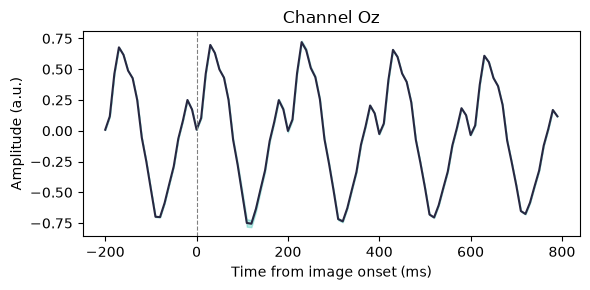

In [4]:
r.plot_erp(np.mean(eegs, axis=0), info, times, "Oz", scale=1, unit="a.u.")
plt.tight_layout()
plt.show()

## 2. Create the EEG RDMs

At every time point, each image gives a pattern across the electrodes. The EEG RDM holds, for every pair of images, how different these two patterns are (1 minus the correlation).

`r.eeg_rdms` returns one RDM per time point for each participant, each stored as the numbers above the diagonal of the table.

per participant (time points, image pairs): (100, 19900)


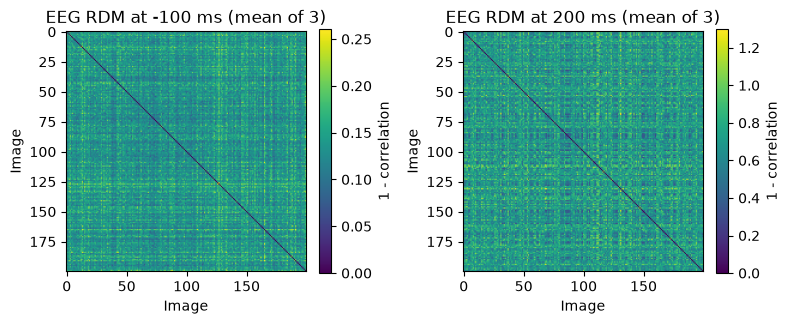

In [5]:
eeg_rdms = [r.eeg_rdms(e) for e in eegs]
print("per participant (time points, image pairs):", eeg_rdms[0].shape)

before = np.argmin(np.abs(times + 0.1))
during = np.argmin(np.abs(times - 0.2))
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, i in zip(axes, (before, during)):
    im = ax.imshow(np.mean([r.rdm(e[:, :, i]) for e in eegs], axis=0), cmap="viridis")
    ax.set(title=f"EEG RDM at {times[i] * 1000:.0f} ms (mean of {len(eegs)})", xlabel="Image", ylabel="Image")
    plt.colorbar(im, ax=ax, label="1 - correlation", fraction=0.046)
plt.tight_layout()
plt.show()

## 3. Load the pretrained model

ResNet-50 from torchvision, pretrained on ImageNet. `weights.transforms()` is the preprocessing the model was trained with (resize, crop, normalise). The first run downloads the weights.

In [6]:
from torchvision.models import resnet50, ResNet50_Weights

weights = ResNet50_Weights.IMAGENET1K_V1
model = resnet50(weights=weights if USE_PRETRAINED else None)
print("last layers:", [n for n, _ in model.named_modules()][-4:])

images = r.load_images(stim, weights.transforms())                 # same order as the EEG images
images.shape

last layers: ['layer4.2.bn3', 'layer4.2.relu', 'avgpool', 'fc']


torch.Size([200, 3, 224, 224])

## 4. Create the model RDMs

The activity of the last layer before the classifier (`avgpool`, 2048 numbers per image), then for every pair of images: 1 minus the correlation.

In [7]:
for n, _ in model.named_modules():
    print(n)


conv1
bn1
relu
maxpool
layer1
layer1.0
layer1.0.conv1
layer1.0.bn1
layer1.0.conv2
layer1.0.bn2
layer1.0.conv3
layer1.0.bn3
layer1.0.relu
layer1.0.downsample
layer1.0.downsample.0
layer1.0.downsample.1
layer1.1
layer1.1.conv1
layer1.1.bn1
layer1.1.conv2
layer1.1.bn2
layer1.1.conv3
layer1.1.bn3
layer1.1.relu
layer1.2
layer1.2.conv1
layer1.2.bn1
layer1.2.conv2
layer1.2.bn2
layer1.2.conv3
layer1.2.bn3
layer1.2.relu
layer2
layer2.0
layer2.0.conv1
layer2.0.bn1
layer2.0.conv2
layer2.0.bn2
layer2.0.conv3
layer2.0.bn3
layer2.0.relu
layer2.0.downsample
layer2.0.downsample.0
layer2.0.downsample.1
layer2.1
layer2.1.conv1
layer2.1.bn1
layer2.1.conv2
layer2.1.bn2
layer2.1.conv3
layer2.1.bn3
layer2.1.relu
layer2.2
layer2.2.conv1
layer2.2.bn1
layer2.2.conv2
layer2.2.bn2
layer2.2.conv3
layer2.2.bn3
layer2.2.relu
layer2.3
layer2.3.conv1
layer2.3.bn1
layer2.3.conv2
layer2.3.bn2
layer2.3.conv3
layer2.3.bn3
layer2.3.relu
layer3
layer3.0
layer3.0.conv1
layer3.0.bn1
layer3.0.conv2
layer3.0.bn2
layer3.0.conv

features: (200, 100352)


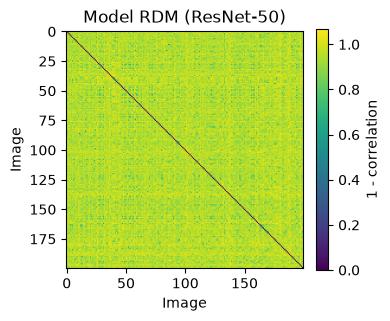

In [8]:
features = r.extract_features(images, model, layer="layer4.2.bn3")
model_rdm = r.rdm(features)
print("features:", features.shape)

fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(model_rdm, cmap="viridis")
ax.set(title="Model RDM (ResNet-50)", xlabel="Image", ylabel="Image")
plt.colorbar(im, ax=ax, label="1 - correlation", fraction=0.046)
plt.tight_layout()
plt.show()

## 5. RSA: compare the two

For each participant and each time point, the Spearman correlation between the model's table and the brain's table (the numbers above the diagonal). Then the mean and the standard error across participants.

3 participants. Peak RSA 0.124 at 130 ms


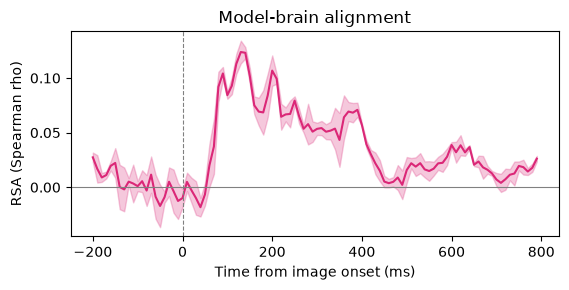

In [9]:
rsa = np.stack([r.spearman(r.upper(model_rdm), x) for x in eeg_rdms])   # (participants, time points)
mean, sem = rsa.mean(0), rsa.std(0) / np.sqrt(len(rsa))
peak = mean.argmax()
print(f"{len(eegs)} participants. Peak RSA {mean[peak]:.3f} at {times[peak] * 1000:.0f} ms")

ax = r.plot_rsa_timecourse(times, mean)
ax.fill_between(times * 1000, mean - sem, mean + sem, color="#DB2777", alpha=0.25)
plt.tight_layout()
plt.savefig(OUT_DIR / "rsa_timecourse.png", dpi=150)
plt.show()

The two tables side by side at the time of the peak (brain: mean over participants):

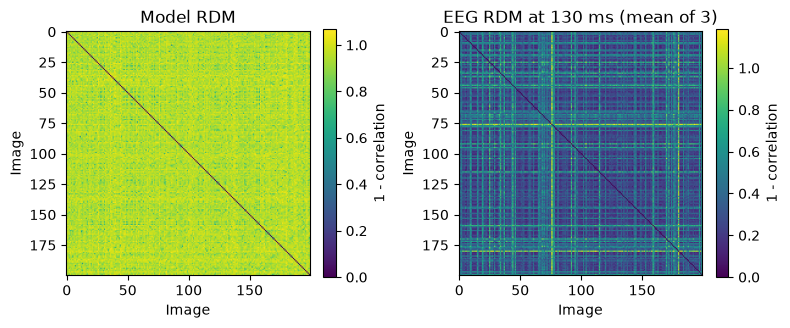

In [10]:
brain_rdm = np.mean([r.rdm(e[:, :, peak]) for e in eegs], axis=0)
r.plot_rdms(model_rdm, brain_rdm, f"EEG RDM at {times[peak] * 1000:.0f} ms (mean of {len(eegs)})")
plt.tight_layout()
plt.savefig(OUT_DIR / "rdms.png", dpi=150)
plt.show()

## 6. Topomaps: where on the head?

The same analysis for every electrode and its 8 nearest neighbours, at every time point, averaged over participants, then played as an animation. EEG blurs the signal, so read it as a rough picture of where on the scalp the signal is strongest, not as brain areas. (For an .mp4 instead of a .gif, use a path ending in `.mp4`; it needs ffmpeg.)

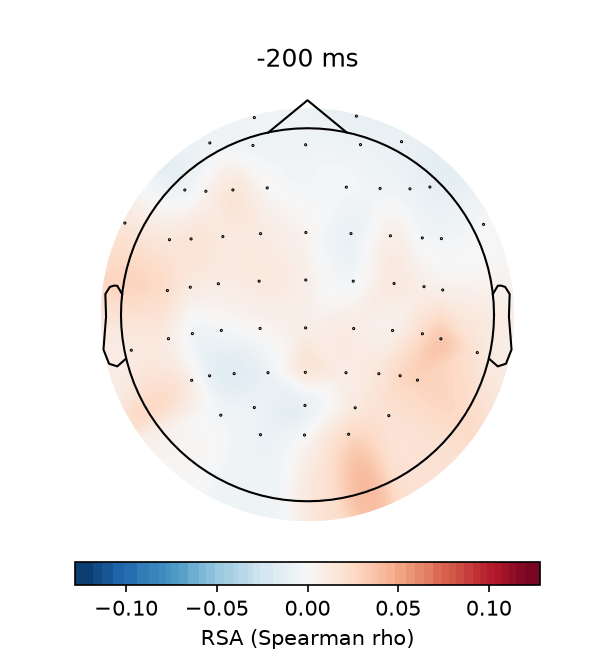

In [11]:
rsa_map = np.stack([r.rsa_searchlight(e, info, model_rdm, n_neighbors=8) for e in eegs]).mean(0)
r.animate_topomap(rsa_map, info, times, OUT_DIR / "rsa_topomap.gif", fps=8, step=2)
Image(filename=OUT_DIR / "rsa_topomap.gif")